<a href="https://colab.research.google.com/github/CelestialBeing001G/Temporary_add_to_version_control/blob/main/dissertation_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Topic Modelling of the SAFE@HOME Literature

This notebook applies Latent Dirichlet Allocation (LDA) to a corpus of 26 papers on home care
safety, and compares the resulting topics against the ten CMO (Context–Mechanism–Outcome)
theories developed from the same literature.

## Pipeline

**Text extraction** (`extract_text.py`, run separately). PDFs are read with `pdfplumber`.
Because most of the papers are typeset in two columns, pages are split at the column gutter and
read column by column rather than straight across, which otherwise interleaves text from the two
columns. Words broken across line breaks are rejoined, filenames and text are normalised to
Unicode NFC, and the script verifies that the number of documents extracted matches the number
in the reference list.

**Preprocessing.** Reference lists are removed before analysis, since bibliographies otherwise
contribute a large share of tokens and cause topics to form around citation artefacts. Text is
lemmatised with spaCy, and stop words include publisher and indexing terms (`doi`, `wiley`,
journal abbreviations) and the surnames of authors in the corpus, both of which otherwise appear
as defining keywords.

**Model selection.** Fit settings and topic count were chosen from diagnostics rather than from
coherence alone. Coherence ($C_v$) rises as a model fragments — on this corpus it peaks at 15
topics, where two topics go unused — so it was read alongside further diagnostics,
chiefly:

- *keyword overlap*: mean pairwise overlap of the top-10 keywords across topics, which detects
  topics that have not separated;
- *dominant-topic probability*: how concentrated each document's topic distribution is.

These are reported together because an undertrained model produces low concentration for the
wrong reason: with no distinct topics to assign to, it spreads every document thinly.

**Final model.** Nine topics, 15 passes and a document–topic prior fixed at alpha = 50/K (5.56 per topic). Nine is the count with the highest coherence among those with no unused topics; the prior follows Griffiths and Steyvers (2004) rather than being tuned. The prior check refits the model under three alternative priors: most topics are recovered under each, but at least one topic has no clear counterpart, and weaker priors concentrate each paper on fewer topics.

## Outputs

- Top keywords per topic, with a keyword-overlap check
- An interactive pyLDAvis chart
- A bipartite map of topics to documents
- A tripartite map placing the ten CMO theories alongside, so the unsupervised topics and the
  manually coded theories can be compared through the documents they share

The CMO links are transcribed from the theory document and matched by citation. They are manual
codings and carry no probability, so they are drawn uniformly and should not be compared with the
topic edges on thickness.

## Limitations

- **Corpus size.** 26 documents is small for LDA. Most documents load principally on one topic,
  and single-document topics occur where a paper has vocabulary no other paper shares.
- **Weakly supported assignments.** Some documents are assigned to a topic with high probability
  but contain few of that topic's keywords; the per-document diagnostic reports keyword support
  per 1,000 tokens and flags these. Short papers are particularly prone to this, and their
  dominant topics should be treated as provisional.
- **Eight papers feed into no CMO theory.** These are the scoping-search papers rather than theory
  sources, so they appear in the topic maps without CMO links by design.
- **Edge threshold in the topic maps.** Documents are linked to their top three topics holding at
  least 3% probability, so the drawn edges do not represent a document's full distribution. The
  map cell reports the coverage; set `WEIGHT_BY_PROBABILITY = True` to draw the full distribution
  instead, in which case each document's edges sum to 1.0.

## Reproducing

The notebook expects `extracted_papers.json` (produced by `extract_text.py`) at the path set in
the loading cell. Run the cells in order from the top; the diagnostic cell must run before the
training cell, since it sets the fit parameters the model uses.

In [ ]:
!pip install --upgrade jupyter_client

# Mount Google Drive

To access the PDF papers directly from Google Drive folder.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Install Required Libraries

This cell installs essential packages for PDF parsing (pdfplumber), NLP processing (spacy, nltk), topic modeling (gensim, pyLDAvis), and network visualisation (networkx).

In [ ]:
# Install libraries for PDF reading, NLP, LDA, and Network Visualisations
!pip install -q pdfplumber gensim pyLDAvis spacy networkx pandas matplotlib seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 57.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 42.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 67.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 76.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 80.6 MB/s eta 0:00:00


# Import Modules & Download NLP Assets

This cell imports all required modules and downloads the necessary language models (NLTK stopwords and spaCy English model) required for text cleaning and lemmatisation.

In [ ]:
#import warnings
#warnings.filterwarnings("ignore", category=DeprecationWarning)

import os
import re
import pandas as pd
import numpy as np
import pdfplumber

# NLP Libraries
import nltk
from nltk.corpus import stopwords
import spacy

# Gensim & LDA Topic Modeling
import gensim
import gensim.corpora as corpora
from gensim.models import LdaModel, CoherenceModel

# Visualisation Libraries
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

# Download NLTK datasets
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)

# Load spaCy English pipeline for lemmatization (disabling unused components for speed)
try:
    nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
except OSError:
    !python -m spacy download en_core_web_sm
    nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

print("Environment setup complete. All libraries and language models are ready.")

Environment setup complete. All libraries and language models are ready.


Instantly read the JSON file directly into a Pandas DataFrame to immediately begin NLP cleaning and LDA topic modeling.

In [ ]:
#import warnings
#warnings.filterwarnings("ignore", category=DeprecationWarning)

import pandas as pd

# Update this path if you saved the JSON file in a different Drive folder
JSON_FILE_PATH = '/content/drive/MyDrive/extracted_papers.json'

# Load the JSON directly into a DataFrame
df_papers = pd.read_json(JSON_FILE_PATH)

print(f"Successfully loaded {len(df_papers)} papers into the DataFrame.")

# Display the first few rows to verify the output
df_papers.head()

Successfully loaded 26 papers into the DataFrame.


,Title,Raw_Text
0,Cao et al. - 2022 - What influences informal c...,"OPENACCESS\nEDITEDBY\nDorinaCadar,\nBrightonan..."
1,EBSCO-FullText-09_05_2026.pdf,FEATURE ARTICLE\nHOME CARE AND HOME\nSUPPORT W...
2,Glomsås et al. - 2022 - Family caregivers’ inv...,Family caregivers’ involvement in caring\nfor ...
3,Häikiö et al. - 2019 - Dementia and patient sa...,Dementia and patient safety in the\nHäikiöetal...
4,Healey et al (2021) IEA conference paper.pdf,Home care support for older adults in England:...


Once the text is extracted, it needs to be cleaned so the LDA algorithm does not cluster useless words together.

This next block uses gensim to strip punctuation and spaCy to lemmatise the words (e.g., turning "caring", "cares", and "cared" all into the base word "care"). It also filters out standard English stop-words and some common academic noise like "et" and "al".

In [ ]:
from gensim.utils import simple_preprocess
import re
import unicodedata

# ---------------------------------------------------------------------------
# TOGGLES -- flip either to False to reproduce the earlier behaviour.
# ---------------------------------------------------------------------------
# Reference lists are ~19% of the average paper here and were leaking citation
# debris into the topics (doi, wiley, journal abbreviations, cited authors'
# surnames). Cutting at the last "References"/"Bibliography" heading removes it.
STRIP_REFERENCES = True
# Publisher / PDF-furniture terms that describe the document format rather than
# its content.
USE_EXTENDED_STOPWORDS = True
# ---------------------------------------------------------------------------

# 1. Custom stop-words: PDF formatting quirks and academic filler
custom_stop_words = ['et', 'al', 'etal', 'figure', 'table', 'study', 'participant']

# Publisher, indexing and journal-furniture terms. These showed up directly in
# the trained topic keywords, so they were shaping clusters.
publisher_stop_words = [
    'doi', 'wiley', 'library', 'springer', 'elsevier', 'sagepub', 'sage',
    'biomedcentral', 'frontiersin', 'pubmed', 'crossref', 'issn', 'isbn',
    'pmid', 'copyright', 'license', 'licence', 'creativecommons', 'commons',
    'permission', 'download', 'downloaded', 'journal', 'vol', 'volume',
    'issue', 'page', 'pages', 'http', 'https', 'www', 'article', 'author',
    'publish', 'publisher', 'press', 'cambridge', 'oxford', 'reprint',
    'supplementary', 'appendix', 'abstract', 'keyword', 'correspondence',
    'accepted', 'received', 'revised', 'submit', 'manuscript', 'editor',
    'peer', 'review', 'affiliation', 'university', 'faculty', 'department',
    'res', 'int', 'nurs', 'geriatrics', 'gerontology', 'bmchealthservicesresearch',
    'bmc', 'sub', 'doi',
]

# Surnames of authors in this corpus. Papers cite themselves and carry running
# headers, so author names survive cleaning and can end up defining a topic --
# in the 14-topic run, Topics 8, 9 and 11 were keyed by "yin", "zhou" and
# "baker", i.e. they had become "the Yin paper", "the Zhou paper" and "the
# Baker paper". Those are citation artifacts, not themes.
# Short names (under 3 characters) are already dropped by the length filter.
author_stop_words = [
    'abrams', 'baker', 'blais', 'borell', 'borson', 'cao', 'chou', 'cowdell',
    'devik', 'donaldson', 'enmarker', 'flintoft', 'fossum', 'freburger',
    'glomsas', 'gyi', 'haighton', 'haikio', 'halvorsen', 'healey', 'hignett',
    'husebo', 'iaboni', 'ishado', 'jacobsen', 'johannessen', 'kankkunen',
    'kiljunen', 'knutsen', 'lang', 'lehtio', 'liden', 'lindberg',
    'lutz', 'macdonald', 'manthorpe', 'mathiesen', 'mclean', 'nichol',
    'nilsen', 'ofsti', 'palmer', 'phelan', 'porter', 'puaschitz',
    'ristolainen', 'rodakowski', 'rosenberg', 'rosengren', 'rugkasa',
    'sadak', 'sagbakken', 'samsi', 'sandberg', 'schildmeijer', 'shakespeare',
    'silverglow', 'steer', 'stevenson', 'stockl', 'storch', 'szemberg',
    'terhorst', 'thakkar', 'tiilikainen', 'vandrevala', 'varjakoski',
    'vercauteren', 'wijk', 'wojtak', 'yin', 'zhou',
]

if USE_EXTENDED_STOPWORDS:
    custom_stop_words = custom_stop_words + publisher_stop_words + author_stop_words

# 2. Explicitly update the active spaCy vocabulary
for word in custom_stop_words:
    nlp.vocab[word].is_stop = True


def strip_reference_list(text):
    """Cut everything after the last References/Bibliography heading."""
    pattern = re.compile(
        r'\n\s*(references|bibliography|reference list)\s*\n', re.IGNORECASE)
    matches = list(pattern.finditer(text))
    if matches:
        return text[:matches[-1].start()]
    return text


def preprocess_text(texts):
    cleaned_texts = []
    n_stripped = 0
    for doc in texts:
        # Normalise Unicode first. Titles/text coming off macOS can be NFD
        # (decomposed), which makes "Haikio"-style names compare unequal to the
        # same string typed as NFC elsewhere in the notebook.
        doc = unicodedata.normalize('NFC', str(doc))

        if STRIP_REFERENCES:
            before = len(doc)
            doc = strip_reference_list(doc)
            if len(doc) < before:
                n_stripped += 1

        # Remove newlines, emails, and URLs
        doc = re.sub(r'\s+', ' ', doc)
        doc = re.sub(r'\S*@\S*\s?', '', doc)
        doc = re.sub(r'http\S+', '', doc)

        # Process with spaCy to preserve POS context for accurate lemmatization
        spacy_doc = nlp(doc)

        # Extract lemmas, filter stop-words, retain valid alphabetic tokens.
        # NOTE: token.is_stop is case-sensitive, so setting
        # nlp.vocab['study'].is_stop = True does NOT catch "Study" or "STUDY".
        # The explicit lowercase check below catches those too.
        lemmatized_tokens = [
            token.lemma_.lower() for token in spacy_doc
            if not token.is_stop
            and token.lemma_.lower() not in custom_stop_words
            and token.is_alpha
            and len(token.lemma_) > 2
        ]

        cleaned_texts.append(lemmatized_tokens)

    if STRIP_REFERENCES:
        print(f"Reference lists stripped from {n_stripped} of {len(texts)} documents.")
        print("(The rest had no detectable 'References' heading -- their reference")
        print(" lists are still in the corpus. Worth a look if topics stay noisy.)")

    return cleaned_texts


print("Starting text preprocessing...")

# Extract the 'Raw_Text' column from the DataFrame into a list
document_texts = df_papers['Raw_Text'].tolist()

processed_docs = preprocess_text(document_texts)
print(f"Successfully cleaned and tokenized {len(processed_docs)} documents.")

Starting text preprocessing...
Reference lists stripped from 25 of 26 documents.
(The rest had no detectable 'References' heading -- their reference
 lists are still in the corpus. Worth a look if topics stay noisy.)
Successfully cleaned and tokenized 26 documents.


In [ ]:
# Which paper kept its reference list? (reported in Section 3.2)
# Run after the preprocessing cell above, which defines strip_reference_list().
# This only reports; it does not change the corpus or any results.
import unicodedata

kept = []
for title, text in zip(df_papers['Title'], df_papers['Raw_Text']):
    t = unicodedata.normalize('NFC', str(text))
    if strip_reference_list(t) == t:
        kept.append(title)

if kept:
    for title in kept:
        print("Reference list kept:", title)
else:
    print("Every paper had its reference list removed.")


Reference list kept: Yin et al. - 2023 - Risk factors associated with home care safety for older people with dementia family caregivers’ per.pdf


The final step before topic modeling is converting cleaned words into a mathematical format the LDA algorithm can read.

This block creates a Dictionary (an index of every unique word) and a Corpus (a term-document frequency matrix that counts how often each word appears in each specific paper). It also filters out words that are too rare or too common to be useful for defining distinct themes.

In [ ]:
import gensim.corpora as corpora

# Create the Dictionary (id2word)
id2word = corpora.Dictionary(processed_docs)

# Filter extremes:
# Remove words that appear in less than 2 documents
# Remove words that appear in more than 50% of the documents (too common to form a distinct topic)
id2word.filter_extremes(no_below=2, no_above=0.5)

# Create the Corpus: Term Document Frequency (Bag of Words)
corpus = [id2word.doc2bow(text) for text in processed_docs]

print(f"Dictionary size: {len(id2word)} unique tokens.")
print(f"Corpus size: {len(corpus)} documents ready for LDA clustering.")

Dictionary size: 2744 unique tokens.
Corpus size: 26 documents ready for LDA clustering.


# Topic Model Diagnostics

Run this **before** training. Stage 1 sweeps the fit settings (`passes`, `alpha`); Stage 2
sweeps the topic count using whatever Stage 1 selects.

Four numbers are reported, because none of them is reliable alone:

- `dom.prob` — how concentrated each document's topic distribution is.
- `overlap` — mean pairwise keyword overlap between topics. **Lower is better.**
- `maxw` — mean top word weight per topic. Very low means undertrained.
- `dead` — topics holding almost no document mass.

The reason for four: an undertrained model has no distinct topics to assign documents to, so it
spreads them thinly and produces a *low* `dom.prob` that looks exactly like healthy mixed
membership. Concentration and undertraining are indistinguishable on `dom.prob` alone, so it is
always read against `overlap` and `maxw`.

The chosen settings are stored in `LDA_PASSES` and `LDA_ALPHA` and picked up by the training
cell below.

STAGE 1: how do the fit settings affect the model?
(topic count held at 9)
  lower dom.prob = documents more mixed BUT may just mean undertrained
  lower overlap  = topics more distinct  (this is the check on that)
  higher maxw    = topics more sharply defined

 passes      alpha  dom.prob  overlap     maxw  topics>10%  dead
--------------------------------------------------------------------
      1  symmetric     0.836    0.180   0.0085        1.69     0
      1       50/K     0.507    0.294   0.0065        2.42     0
      1       10.0     0.336    0.387   0.0061        3.50     0
      1       50.0     0.123    0.582   0.0056        8.54     0
      5  symmetric     0.953    0.013   0.0300        1.12     0
      5       50/K     0.821    0.013   0.0288        1.31     0
      5       10.0     0.716    0.025   0.0219        1.54     0
      5       50.0     0.259    0.194   0.0097        4.38     0
     15  symmetric     0.954    0.012   0.0334        1.15     0
     15       50/K

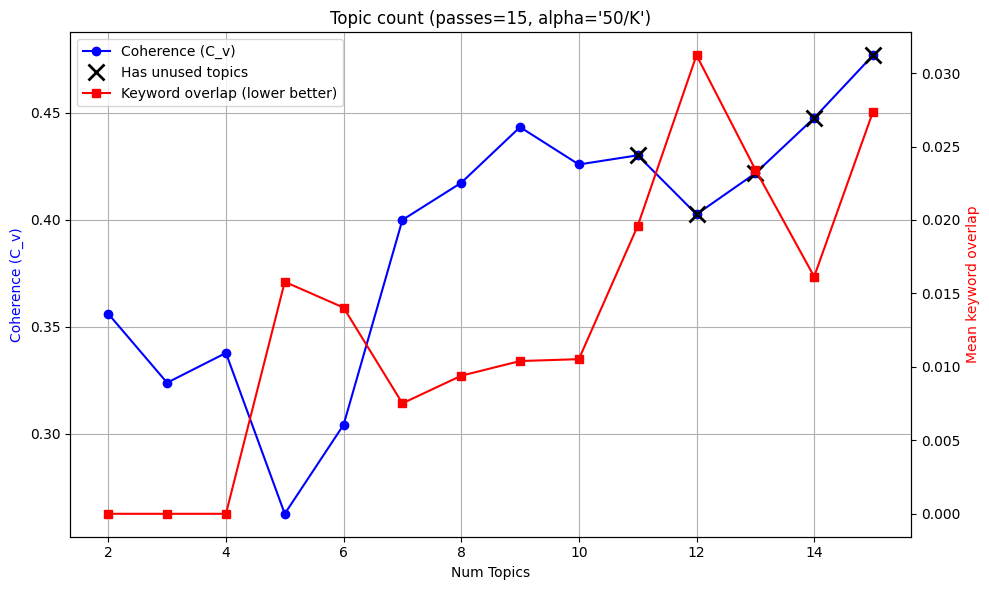

 topics      C_v  dom.prob  overlap     maxw  dead   note
----------------------------------------------------------------------------
      2   0.3561     0.856    0.000   0.0092     0   documents near single-topic
      3   0.3239     0.826    0.000   0.0132     0   
      4   0.3378     0.812    0.000   0.0186     0   
      5   0.2627     0.819    0.016   0.0184     0   
      6   0.3042     0.806    0.014   0.0245     0   
      7   0.3999     0.789    0.008   0.0269     0   
      8   0.4172     0.810    0.009   0.0321     0   
      9   0.4433     0.803    0.010   0.0341     0   
     10   0.4258     0.816    0.011   0.0328     0   
     11   0.4301     0.804    0.020   0.0294     1   1 unused
     12   0.4025     0.778    0.031   0.0260     2   2 unused
     13   0.4217     0.805    0.023   0.0276     2   2 unused
     14   0.4475     0.824    0.016   0.0333     1   1 unused
     15   0.4768     0.835    0.027   0.0272     2   2 unused

Coherence spans 0.214, peaking at 15 topi

In [ ]:
# ===========================================================================
# TOPIC MODEL DIAGNOSTICS -- two stages
#
# Stage 1: are the fit settings sane?   Stage 2: how many topics?
#
# FOUR numbers, because no single one of them is trustworthy alone:
#
#   dom.prob    mean probability of each document's dominant topic.
#               ~0.30-0.60 mixed | ~0.60-0.85 moderately concentrated |
#               ~0.85-1.00 effectively one topic per document.
#
#   overlap     mean pairwise Jaccard overlap of the top-10 keywords across
#               topics. LOW is good: topics own distinct vocabulary. High means
#               they are smearing into each other.
#
#   maxw        mean top word weight per topic. Very low means no word is
#               strongly attached to any topic -- a sign of undertraining.
#
#   dead        topics holding almost no document mass.
#
# WHY FOUR: an undertrained model has no distinct topics to assign documents to,
# so it spreads every document thinly across all of them -- which produces a LOW
# dom.prob that looks exactly like healthy mixed membership. Undertraining and
# genuine mixed membership are indistinguishable on dom.prob alone. Reading it
# on its own is what pushed this notebook to passes=1 and a smeared model.
# Always check dom.prob against overlap and maxw.
# ===========================================================================
import logging
import itertools
logging.getLogger('gensim').setLevel(logging.ERROR)


def diagnose(model, corpus, num_topics, topn=10):
    """Returns (dom.prob, mean topics>10%, dead topics, keyword overlap, mean top weight)."""
    dists = [model.get_document_topics(bow, minimum_probability=0.0)
             for bow in corpus]
    dom = sum(max(p for _, p in d) for d in dists) / len(dists)
    above10 = sum(sum(1 for _, p in d if p >= 0.10) for d in dists) / len(dists)
    mass = [0.0] * num_topics
    for d in dists:
        for t, p in d:
            mass[t] += p
    dead = sum(1 for m in mass if m < 0.5)

    tops = [model.show_topic(t, topn=topn) for t in range(num_topics)]
    sets = [{w for w, _ in tt} for tt in tops]
    maxw = sum(tt[0][1] for tt in tops if tt) / max(num_topics, 1)
    if num_topics > 1:
        pairs = list(itertools.combinations(range(num_topics), 2))
        overlap = sum(len(sets[a] & sets[b]) / max(len(sets[a] | sets[b]), 1)
                      for a, b in pairs) / len(pairs)
    else:
        overlap = 0.0
    return dom, above10, dead, overlap, maxw


def resolve_alpha(alpha, num_topics):
    """'50/K' -> 50/num_topics per topic. Anything else goes to gensim unchanged."""
    return 50.0 / num_topics if alpha == '50/K' else alpha


# ---------------------------------------------------------------------------
# STAGE 1 -- fit settings, topic count held fixed
# ---------------------------------------------------------------------------
DIAG_TOPICS = 9   # hold at the topic count you actually intend to use

print("STAGE 1: how do the fit settings affect the model?")
print(f"(topic count held at {DIAG_TOPICS})")
print("  lower dom.prob = documents more mixed BUT may just mean undertrained")
print("  lower overlap  = topics more distinct  (this is the check on that)")
print("  higher maxw    = topics more sharply defined\n")
print(f"{'passes':>7} {'alpha':>10} {'dom.prob':>9} {'overlap':>8} {'maxw':>8} "
      f"{'topics>10%':>11} {'dead':>5}")
print("-" * 68)

setting_results = []
for passes in [1, 5, 15, 25]:
    for alpha in ['symmetric', '50/K', 10.0, 50.0]:
        m = LdaModel(corpus=corpus, id2word=id2word, num_topics=DIAG_TOPICS,
                     random_state=42, passes=passes,
                     alpha=resolve_alpha(alpha, DIAG_TOPICS))
        dom, above10, dead, overlap, maxw = diagnose(m, corpus, DIAG_TOPICS)
        setting_results.append({'passes': passes, 'alpha': alpha, 'dom': dom,
                                'above10': above10, 'dead': dead,
                                'overlap': overlap, 'maxw': maxw})
        print(f"{passes:7d} {str(alpha):>10} {dom:9.3f} {overlap:8.3f} {maxw:8.4f} "
              f"{above10:11.2f} {dead:5d}")

# SELECTION
#
# The automatic rule below ranks settings by keyword overlap, then by how mixed
# the documents are. Once passes >= 5, the overlap differences between priors
# amount to a few shared keywords across all 36 topic pairs, so in practice the
# rule picks whichever prior makes documents look most mixed. A large alpha
# produces that mixing by itself (alpha=50 adds 50 pseudo-counts to every
# topic in every document), so choosing it on that basis is circular.
#
# The prior is therefore fixed at 50/K per topic (Griffiths and Steyvers, 2004),
# which adds 50 pseudo-counts in total whatever K is. The automatic pick is kept
# as a comparison case in the prior check cell after training.
candidates = [r for r in setting_results if r['dead'] == 0] or setting_results
best_overlap = min(r['overlap'] for r in candidates)
distinct = [r for r in candidates if r['overlap'] <= best_overlap * 1.25]
pick = min(distinct, key=lambda r: (r['dom'], r['passes']))
print(f"\nAutomatic rule would pick passes={pick['passes']}, alpha={pick['alpha']!r} "
      f"(overlap {pick['overlap']:.3f}, dom.prob {pick['dom']:.3f})")

FIX_PRIOR_50_OVER_K = True   # False restores the automatic pick

if FIX_PRIOR_50_OVER_K:
    LDA_PASSES, LDA_ALPHA = 15, '50/K'
    print(f"-> Using passes={LDA_PASSES}, alpha=50/K "
          f"(= {50.0 / DIAG_TOPICS:.2f} per topic at K={DIAG_TOPICS})")
    print("   Fixed prior, not selected by the rule above. Check that the 50/K rows")
    print("   in the Stage 1 table are stable by 15 passes.")
else:
    LDA_PASSES, LDA_ALPHA = pick['passes'], pick['alpha']
    print(f"-> Using the automatic pick: passes={LDA_PASSES}, alpha={LDA_ALPHA!r}")

# ---------------------------------------------------------------------------
# STAGE 2 -- topic count, using the settings above
# ---------------------------------------------------------------------------
print("\n" + "=" * 72)
print(f"STAGE 2: topic count (passes={LDA_PASSES}, alpha={LDA_ALPHA!r})\n")


def evaluate_topic_counts(dictionary, corpus, texts, limit, start=2, step=1):
    model_list, results = [], []
    for num_topics in range(start, limit, step):
        model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=num_topics,
                         random_state=42, passes=LDA_PASSES,
                         alpha=resolve_alpha(LDA_ALPHA, num_topics))
        model_list.append(model)
        coherence = CoherenceModel(model=model, texts=texts, dictionary=dictionary,
                                   coherence='c_v').get_coherence()
        dom, above10, dead, overlap, maxw = diagnose(model, corpus, num_topics)
        results.append({'num_topics': num_topics, 'coherence': coherence,
                        'dom_prob': dom, 'above10': above10, 'dead': dead,
                        'overlap': overlap, 'maxw': maxw})
    return model_list, results


start = 2; limit = 16; step = 1
model_list, results = evaluate_topic_counts(
    dictionary=id2word, corpus=corpus, texts=processed_docs,
    start=start, limit=limit, step=step)
coherence_values = [r['coherence'] for r in results]

import matplotlib.pyplot as plt
x = [r['num_topics'] for r in results]
fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.plot(x, coherence_values, marker='o', color='b', label='Coherence (C_v)')
ax1.set_xlabel("Num Topics"); ax1.set_ylabel("Coherence (C_v)", color='b')
ax1.grid(True)
ax2 = ax1.twinx()
ax2.plot(x, [r['overlap'] for r in results], marker='s', color='r',
         label='Keyword overlap (lower better)')
ax2.set_ylabel("Mean keyword overlap", color='r')
bad = [r['num_topics'] for r in results if r['dead'] > 0]
if bad:
    ax1.plot(bad, [r['coherence'] for r in results if r['dead'] > 0], 'kx',
             markersize=12, markeredgewidth=2, label='Has unused topics')
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [l.get_label() for l in lines], loc='best')
plt.title(f"Topic count (passes={LDA_PASSES}, alpha={LDA_ALPHA!r})")
plt.tight_layout(); plt.show()

print(f"{'topics':>7} {'C_v':>8} {'dom.prob':>9} {'overlap':>8} {'maxw':>8} "
      f"{'dead':>5}   note")
print("-" * 76)
for r in results:
    notes = []
    if r['dead'] > 0:
        notes.append(f"{r['dead']} unused")
    if r['overlap'] > 0.25:
        notes.append("topics overlap heavily")
    if r['dom_prob'] >= 0.85:
        notes.append("documents near single-topic")
    print(f"{r['num_topics']:7d} {r['coherence']:8.4f} {r['dom_prob']:9.3f} "
          f"{r['overlap']:8.3f} {r['maxw']:8.4f} {r['dead']:5d}   {'; '.join(notes)}")

usable = [r for r in results if r['dead'] == 0 and r['overlap'] <= 0.25]
print()
_spread = max(coherence_values) - min(coherence_values)
if _spread < 0.10:
    print(f"Coherence spans only {_spread:.3f} across this range -- too flat to")
    print("choose on alone; rely on overlap and interpretability.")
else:
    _peak = max(results, key=lambda r: r['coherence'])
    print(f"Coherence spans {_spread:.3f}, peaking at {_peak['num_topics']} topics "
          f"({_peak['coherence']:.4f}).")
    print("That is real variation, but still check overlap and read the keyword")
    print("lists before committing -- coherence alone has misled this notebook before.")
print()
if usable:
    print("Counts with no unused topics and reasonably distinct topics: "
          f"{', '.join(str(r['num_topics']) for r in usable)}")
else:
    print("No count avoids both unused and heavily-overlapping topics.")
    print("Try raising passes in Stage 1 before lowering the topic count.")
print()
print("Now choose on INTERPRETABILITY: train at two or three candidates, read the")
print("keyword lists, and keep the one whose topics you can name and map onto your")
print("CMO theories. If the topics are distinct but documents each sit on one of")
print("them, that is a real finding about 26 focused papers -- report it as such.")

# Train the LDA Topic Model

An initial baseline of `num_topics=10` was chosen to mirror the 10 CMO theories. The diagnostic
cell **above** was then used to set the fit settings and topic count from the data rather than
by assumption, and the model below is trained with whatever `NUM_TOPICS` you set there.

Fit settings (`passes`, `alpha`) are inherited from Stage 1 of that diagnostic, so the final
model is fitted the same way it was evaluated. The cell stamps a signature that the cells below
print, so an output produced before a retrain identifies itself as stale.

In [ ]:
# Set this from the Stage 2 table in the diagnostic cell above. Choose on
# interpretability -- read the keyword lists at two or three candidate counts --
# rather than on small coherence differences.
NUM_TOPICS = 9

# passes/alpha come from Stage 1 of the diagnostic so the final model is fitted
# the same way it was evaluated. If you have not run that cell yet, sensible
# fallbacks are used.
try:
    _passes, _alpha = LDA_PASSES, LDA_ALPHA
except NameError:
    _passes, _alpha = 1, 'symmetric'
    print("NOTE: the diagnostic cell above has not been run in this session -")
    print("      falling back to passes=1, alpha=symmetric. Run it to choose")
    print("      these from the data instead.")

# '50/K' is resolved here so the prior scales with the topic count.
_alpha_value = 50.0 / NUM_TOPICS if _alpha == '50/K' else _alpha

lda_model = LdaModel(
    corpus=corpus,
    id2word=id2word,
    num_topics=NUM_TOPICS,
    random_state=42,
    update_every=1,
    chunksize=100,
    passes=_passes,
    alpha=_alpha_value,
    per_word_topics=True
)

print(f"Successfully trained LDA model with {NUM_TOPICS} topics "
      f"(passes={_passes}, alpha={_alpha}).")

# --- Model signature ---------------------------------------------------------
# Stamped so downstream cells can show which model their output came from.
# Running a downstream cell BEFORE retraining leaves an output that silently
# describes an older model -- this makes that visible instead.
MODEL_RUN = globals().get('MODEL_RUN', 0) + 1
MODEL_SIG = f"K={NUM_TOPICS}, passes={_passes}, alpha={_alpha!r}, run #{MODEL_RUN}"


def show_model_stamp():
    """Print which model produced this output; warn if it looks stale."""
    try:
        print(f"[model: {MODEL_SIG}]")
        if lda_model.num_topics != NUM_TOPICS:
            print(f"  *** STALE: lda_model has {lda_model.num_topics} topics but "
                  f"NUM_TOPICS is now {NUM_TOPICS}.")
            print("      Re-run the training cell above before trusting this output.")
    except NameError:
        print("[model: not yet trained in this session]")

Successfully trained LDA model with 9 topics (passes=15, alpha=50/K).


# Output Topic Keywords & Calculate Coherence Score

This prints the top 10 keywords for each topic and the model's coherence score ($C_v$).

It also reports **keyword overlap** between topics — mean and worst pair. Overlap is the check
on coherence: an undertrained model produces topics that share vocabulary and spread every
document thinly across them, which flatters the concentration statistic while telling you
nothing. A worst pair above ~0.4 means two topics are near-duplicates; raise `passes` in the
diagnostic cell rather than lowering the topic count.

In [ ]:
# Display top 10 keywords per topic
try:
    show_model_stamp()
except NameError:
    print("[model stamp unavailable - run the training cell above]")


print("--- Extracted Topic Keywords ---")
for idx, topic in lda_model.print_topics(-1, num_words=10):
    print(f"\nTopic {idx + 1}:")
    print(topic)

# Calculate and print Coherence Score
coherence_model = CoherenceModel(
    model=lda_model,
    texts=processed_docs,
    dictionary=id2word,
    coherence='c_v'
)
coherence_score = coherence_model.get_coherence()
print(f"\nModel Coherence Score (C_v): {coherence_score:.4f}")

# --- Distinctiveness check on the trained model ------------------------------
# Heavy keyword sharing between topics means the model has not separated them;
# usually a sign of too few passes rather than too many topics.
import itertools as _it
_sets = [{w for w, _ in lda_model.show_topic(t, topn=10)} for t in range(NUM_TOPICS)]
_pairs = list(_it.combinations(range(NUM_TOPICS), 2))
if _pairs:
    _ov = [(len(_sets[a] & _sets[b]) / max(len(_sets[a] | _sets[b]), 1), a, b)
           for a, b in _pairs]
    _mean = sum(o[0] for o in _ov) / len(_ov)
    _worst = max(_ov)
    # Judge on the WORST pair as well as the mean -- a low mean can hide two
    # topics that are effectively duplicates.
    if _worst[0] > 0.40:
        _verdict = ("NOT separated: at least one pair is near-duplicate. "
                    "Raise passes before lowering the topic count.")
    elif _mean > 0.25:
        _verdict = "topics overlap broadly - try more passes"
    elif _mean <= 0.15:
        _verdict = "good separation"
    else:
        _verdict = "acceptable"
    print(f"\nMean pairwise keyword overlap: {_mean:.3f} "
          f"(worst pair {_worst[0]:.2f}) -- {_verdict}")
    for j, a, b in sorted(_ov, reverse=True)[:3]:
        if j > 0.3:
            print(f"   Topics {a+1} and {b+1} share {int(j*100)}% of their top keywords: "
                  f"{', '.join(sorted(_sets[a] & _sets[b]))}")

[model: K=9, passes=15, alpha='50/K', run #1]
--- Extracted Topic Keywords ---

Topic 1:
0.020*"observation" + 0.013*"copd" + 0.009*"china" + 0.008*"observe" + 0.007*"clinical" + 0.007*"symptom" + 0.007*"bed" + 0.006*"primary" + 0.006*"dna" + 0.005*"judgment"

Topic 2:
0.072*"informal" + 0.060*"adverse" + 0.052*"stroke" + 0.049*"adl" + 0.037*"caregiving" + 0.020*"moderate" + 0.015*"amount" + 0.014*"rate" + 0.013*"effect" + 0.011*"model"

Topic 3:
0.021*"incident" + 0.018*"accident" + 0.013*"drug" + 0.008*"treatment" + 0.008*"sweden" + 0.007*"prescribe" + 0.006*"content" + 0.005*"reporting" + 0.005*"household" + 0.005*"mobile"

Topic 4:
0.069*"exclusion" + 0.061*"exclude" + 0.027*"recipient" + 0.015*"item" + 0.013*"model" + 0.011*"cluster" + 0.010*"homebound" + 0.010*"variable" + 0.009*"finland" + 0.008*"survey"

Topic 5:
0.022*"employer" + 0.020*"british" + 0.020*"trouble" + 0.019*"disabled" + 0.018*"white" + 0.012*"telephone" + 0.011*"informant" + 0.010*"alarm" + 0.010*"employee" + 0.

# Prior Check

Refits the trained model under four document–topic priors, with everything else held fixed:
50/K (the prior used), 50 (the v5.0 setting), gensim's default of 1/K, and a prior learned
from the data (`auto`).

For each prior it reports how much of a document's topic distribution comes from the prior
rather than from the document's words, and whether the topics themselves change or only the
way documents are spread across them. Column definitions are in the cell comments.


In [ ]:
# ===========================================================================
# PRIOR CHECK
#
# Columns
#   prior share   sum(alpha) / (sum(alpha) + document length): the part of a
#                 document's topic distribution supplied by the prior rather
#                 than by its words. Median document, and the worst (shortest).
#   shared kw     top-10 keywords shared between topics, summed over all
#                 topic pairs (0 = every topic has its own vocabulary).
#   match         after pairing each topic one-to-one with its closest topic in
#                 the trained model: top-10 keywords in common (mean, worst).
#   same top      documents whose dominant topic is the paired topic.
#   C_v, dom.prob as in the diagnostic cell.
# ===========================================================================
import itertools
import numpy as np
from scipy.optimize import linear_sum_assignment

try:
    show_model_stamp()
except NameError:
    print("[model stamp unavailable - run the training cell above]")

PRIOR_CASES = [
    ('50/K', '50/K'),
    ('50 (v5.0)', 50.0),
    ('1/K (gensim default)', 'symmetric'),
    ('learned (auto)', 'auto'),
]


def _fit(alpha):
    return LdaModel(corpus=corpus, id2word=id2word, num_topics=NUM_TOPICS,
                    random_state=42, update_every=1, chunksize=100,
                    passes=_passes,
                    alpha=50.0 / NUM_TOPICS if alpha == '50/K' else alpha)


def _top_sets(model):
    return [{w for w, _ in model.show_topic(t, topn=10)} for t in range(NUM_TOPICS)]


def _dominant(model):
    return [max(model.get_document_topics(b, minimum_probability=0.0),
                key=lambda x: x[1])[0] for b in corpus]


doc_len = np.array([sum(c for _, c in bow) for bow in corpus], dtype=float)
ref_sets = _top_sets(lda_model)
ref_dom = _dominant(lda_model)
topic_pairs = list(itertools.combinations(range(NUM_TOPICS), 2))

rows = []
for name, alpha in PRIOR_CASES:
    m = _fit(alpha)
    a_sum = float(np.sum(m.alpha))
    share = a_sum / (a_sum + doc_len)
    sets = _top_sets(m)
    shared_kw = sum(len(sets[a] & sets[b]) for a, b in topic_pairs)
    S = np.array([[len(s & r) for r in ref_sets] for s in sets])
    ri, ci = linear_sum_assignment(-S)
    pairing = dict(zip(ri, ci))
    matched = S[ri, ci]
    same_top = sum(1 for t, r in zip(_dominant(m), ref_dom) if pairing[t] == r)
    dists = [m.get_document_topics(b, minimum_probability=0.0) for b in corpus]
    dom = float(np.mean([max(p for _, p in d) for d in dists]))
    cv = CoherenceModel(model=m, texts=processed_docs, dictionary=id2word,
                        coherence='c_v').get_coherence()
    rows.append(dict(name=name, alpha_sum=a_sum, share_med=float(np.median(share)),
                     share_max=float(share.max()), worst_doc=int(share.argmax()) + 1,
                     shared_kw=shared_kw, match_mean=float(matched.mean()),
                     match_min=int(matched.min()), same_top=same_top, cv=cv, dom=dom))

print(f"Reference: the trained model ({MODEL_SIG})")
print(f"Document length after filtering: median {np.median(doc_len):.0f}, "
      f"shortest {doc_len.min():.0f} tokens\n")
print(f"{'prior':22s} {'sum(alpha)':>10} {'prior share':>13} {'shared kw':>9} "
      f"{'match':>9} {'same top':>9} {'C_v':>7} {'dom.prob':>8}")
print(f"{'':22s} {'':>10} {'med / worst':>13} {'':>9} {'mean/min':>9}")
print("-" * 96)
for r in rows:
    print(f"{r['name']:22s} {r['alpha_sum']:10.2f} "
          f"{r['share_med']:5.1%} / {r['share_max']:5.1%} {r['shared_kw']:9d} "
          f"{r['match_mean']:5.1f} / {r['match_min']:<2d} "
          f"{r['same_top']:>4d}/{len(corpus):<4d} {r['cv']:7.4f} {r['dom']:8.3f}")

print()
for r in rows:
    if r['match_mean'] >= 9.5 and r['same_top'] == len(corpus):
        verdict = "identical to the trained model (reproducibility check)"
    elif r['match_mean'] >= 7 and r['match_min'] >= 5:
        verdict = "same topics; the prior mainly changes how documents spread across them"
    elif r['match_mean'] >= 7:
        verdict = "mostly the same topics, but at least one topic has no clear counterpart"
    elif r['match_mean'] >= 4:
        verdict = "similar topics, some reshaped"
    else:
        verdict = "different topics"
    print(f"{r['name']:22s} -> {verdict}")

worst = max(rows, key=lambda r: r['share_max'])
print(f"\nLargest prior share: {worst['name']} on Doc {worst['worst_doc']} "
      f"({worst['share_max']:.1%} of its topic distribution comes from the prior).")


[model: K=9, passes=15, alpha='50/K', run #1]
Reference: the trained model (K=9, passes=15, alpha='50/K', run #1)
Document length after filtering: median 1072, shortest 278 tokens

prior                  sum(alpha)   prior share shared kw     match  same top     C_v dom.prob
                                    med / worst            mean/min
------------------------------------------------------------------------------------------------
50/K                        50.00  4.5% / 15.2%         7  10.0 / 10   26/26    0.4433    0.803
50 (v5.0)                  450.00 29.6% / 61.8%         3   8.4 / 4    21/26    0.4693    0.420
1/K (gensim default)         1.00  0.1% /  0.4%         8   8.2 / 4    21/26    0.3896    0.954
learned (auto)               0.23  0.0% /  0.1%         8   8.2 / 4    21/26    0.3896    0.956

50/K                   -> identical to the trained model (reproducibility check)
50 (v5.0)              -> mostly the same topics, but at least one topic has no clear counter

# Interactive Topic Visualization (pyLDAvis)

This generates an interactive two-dimensional map directly inside your notebook, allowing you to click through each topic, inspect word frequencies, and see how distinct or overlapping the clusters are.

In [ ]:
#import warnings
#warnings.filterwarnings("ignore", category=DeprecationWarning)

# Enable interactive visualization inside Colab
pyLDAvis.enable_notebook()

# Prepare and render the pyLDAvis dashboard
# sort_topics=False keeps the model's own topic numbering. By default pyLDAvis
# renumbers topics by size, which made its numbers (and both maps, which
# follow it) disagree with the keyword list and the per-document table.
vis_data = gensimvis.prepare(lda_model, corpus, id2word, sort_topics=False)
vis_data

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0     -0.072695  0.087988       1        1  11.853674
1      0.228264  0.137295       2        1   5.026404
2     -0.048736  0.111090       3        1  14.928733
3      0.193071 -0.140115       4        1   6.071298
4     -0.002365 -0.076914       5        1  12.081341
5     -0.107636  0.015833       6        1  16.866490
6     -0.060698 -0.144319       7        1   7.149672
7     -0.044607  0.026476       8        1  12.004868
8     -0.084599 -0.017334       9        1  14.017521, topic_info=           Term        Freq       Total Category  logprob  loglift
480   exclusion  112.000000  112.000000  Default  30.0000  30.0000
155    informal  133.000000  133.000000  Default  29.0000  29.0000
479     exclude  101.000000  101.000000  Default  28.0000  28.0000
12      adverse  110.000000  110.000000  Default  27.0000  27.0000
1709     stroke   69.000000   69.000000  Default  26.0000  26.0000
...         ...         ...         ...      ...      ...      ...
1550   standard   13.925460   31.867737   Topic9  -5.5725   1.1370
664   provision   13.309617   28.070009   Topic9  -5.6177   1.2186
700      search   13.891907   35.568459   Topic9  -5.5749   1.0247
101   encounter   12.647823   28.960546   Topic9  -5.6687   1.1364
889    creative   11.638705   41.897059   Topic9  -5.7519   0.6840

[519 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
2552      8  0.869977  acceptance
1         1  0.037282    accident
1         3  0.869923    accident
1         5  0.037282    accident
1         6  0.024855    accident
...     ...       ...         ...
802       4  0.084551         yes
802       5  0.479121         yes
802       6  0.084551         yes
802       8  0.112734         yes
802       9  0.028184         yes

[1452 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5, 6, 7, 8, 9])

# Build and Plot the Topic-to-Document Network Map

This plots each topic against the documents that load onto it, keeping the model's own topic numbering (pyLDAvis sorting is switched off above), so
Topic n is the same topic here as in the keyword list, the interactive chart and the
per-document table. Documents are labelled by
citation rather than filename.

Note this is a topic-to-*document* map. It is separate from the manual CMO-to-document mapping,
which is drawn from Theories.docx rather than from the model.

[model: K=9, passes=15, alpha='50/K', run #1]


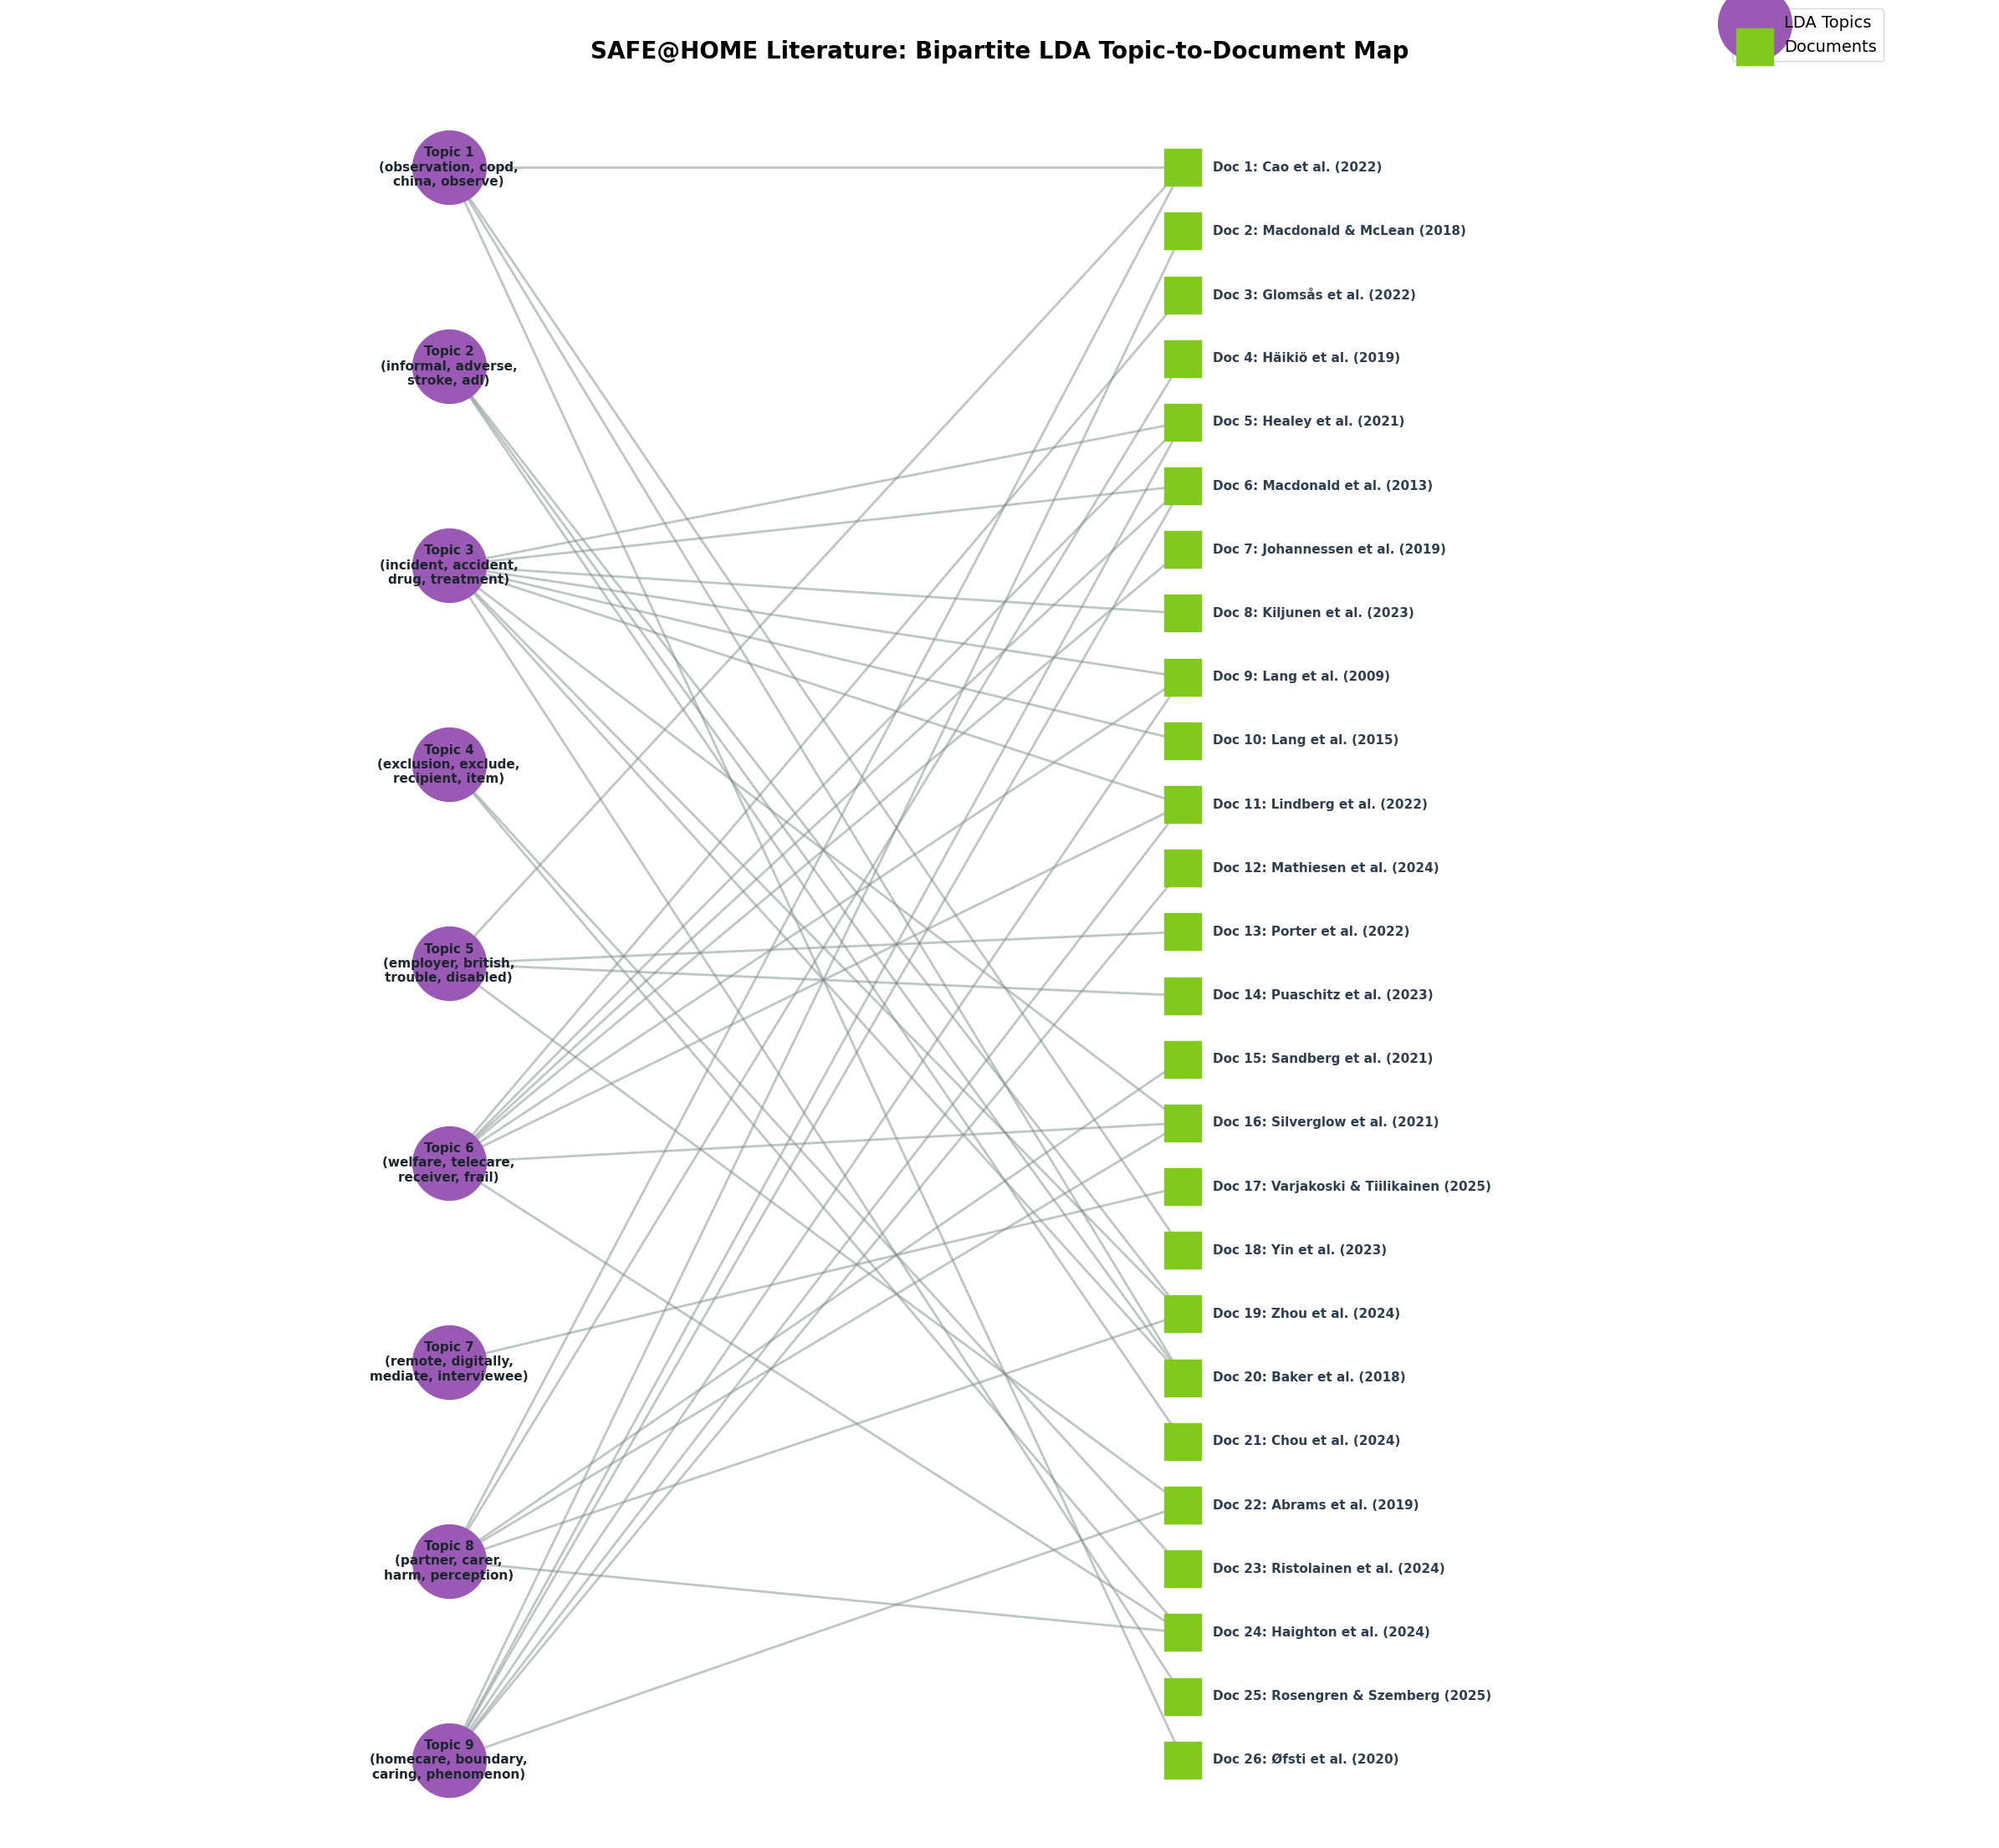

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import re
try:
    show_model_stamp()
except NameError:
    print("[model stamp unavailable - run the training cell above]")



# 1. Initialize Network Graph
G = nx.Graph()
topic_labels_dict = {}

# Pre-generate labels for ALL topics
# pyLDAvis topics are 1-indexed (1 to NUM_TOPICS).
for pyldavis_id in range(1, NUM_TOPICS + 1):
    gensim_id = vis_data.topic_order[pyldavis_id - 1] - 1

    # Extract only the top 4 words to keep the node labels clean and compact
    top_words = [word for word, weight in lda_model.show_topic(gensim_id, topn=4)]

    # Format cleanly: "Topic X\n(word1, word2,\nword3, word4)"
    line1 = ', '.join(top_words[:2])
    line2 = ', '.join(top_words[2:])
    topic_label = f"Topic {pyldavis_id}\n({line1},\n{line2})"

    topic_labels_dict[gensim_id] = topic_label

# 2. Define the Author Mapping Dictionary
# --- Robust title matching -------------------------------------------------
# Titles may arrive composed (NFC) or decomposed (NFD). The two look identical
# but never compare equal. The old key "ikio" only matched Häikiö because the
# decomposed title spells it h a ¨ i k i o ¨ -- once extract_text.py started
# normalising to NFC the name became h ä i k i ö, "ikio" stopped matching, and
# Häikiö silently became "Unknown Author". Folding away diacritics makes the
# match work either way.
import unicodedata


def fold_title(s):
    """Lowercase and strip diacritics so titles match whether NFC or NFD."""
    s = unicodedata.normalize('NFC', str(s)).lower()
    s = s.replace('ø', 'o').replace('æ', 'ae').replace('ß', 'ss').replace('đ', 'd')
    s = unicodedata.normalize('NFD', s)
    return ''.join(c for c in s if not unicodedata.combining(c))


# Keys are plain ASCII so they match the folded title.
# NOTE: there are two Macdonald papers and they need distinct labels:
#   "Home Care Safety Markers..."          -> Macdonald et al. (2013)
#   "Home Care and Home Support Worker..." -> Macdonald & McLean (2018)
#   (Perspectives, 40(1), 18-26; the PDF confirms the 2018 publication.)
# The second arrived as "EBSCO-FullText-09_05_2026.pdf". That filename is
# opaque and will change if you re-download it -- renaming the PDF to something
# like "Macdonald and McLean - 2018 - Support Worker Safety.pdf" (and updating
# the key below to "mclean") would be a lot less fragile.
author_map = {
    "lang et al. - 2009": "Lang et al. (2009)",
    "gbae118": "Ristolainen et al. (2024)",
    "mathiesen": "Mathiesen et al. (2024)",
    "healey": "Healey et al. (2021)",
    "lindberg": "Lindberg et al. (2022)",
    "markers": "Macdonald et al. (2013)",
    "ebsco-fulltext": "Macdonald & McLean (2018)",
    "baker": "Baker et al. (2018)",
    "johannessen": "Johannessen et al. (2019)",
    "sandberg": "Sandberg et al. (2021)",
    "yin": "Yin et al. (2023)",
    "div-class-title": "Abrams et al. (2019)",
    "ofsti": "Øfsti et al. (2020)",
    "chou": "Chou et al. (2024)",
    "zhou": "Zhou et al. (2024)",
    "ijerph": "Haighton et al. (2024)",
    "haikio": "Häikiö et al. (2019)",
    "lang et al. - 2015": "Lang et al. (2015)",
    "cao": "Cao et al. (2022)",
    "kiljunen": "Kiljunen et al. (2023)",
    "varjakoski": "Varjakoski & Tiilikainen (2025)",
    "silverglow": "Silverglow et al. (2021)",
    "puaschitz": "Puaschitz et al. (2023)",
    "glomsas": "Glomsås et al. (2022)",
    "porter": "Porter et al. (2022)",
    "rosengren": "Rosengren & Szemberg (2025)",
}

# --- Guard against stale state ---------------------------------------------
# If the JSON was reloaded without re-running preprocessing, `corpus` and
# `df_papers` fall out of step and every document label silently attaches to
# the wrong paper. Fail loudly instead.
if len(corpus) != len(df_papers):
    raise RuntimeError(
        f"corpus has {len(corpus)} documents but df_papers has {len(df_papers)}. "
        "The notebook has been run out of order -- use Runtime > Restart session "
        "and run all so every cell sees the same data.")

# 3. Collect Valid Edges and Nodes (Capturing Multiple Topics Per Document)
collected_edges = []
active_topics = set()
active_docs = set()

for i, bow in enumerate(corpus):
    raw_title = fold_title(df_papers['Title'].iloc[i])

    # Match the raw title to the clean author citation
    citation = "Unknown Author"
    for key, val in author_map.items():
        if key in raw_title:
            citation = val
            break

    doc_label = f"Doc {i+1}: {citation}"

    # Get true raw probabilities
    topic_distribution = lda_model.get_document_topics(bow, minimum_probability=0.0)

    if topic_distribution:
        # Sort topics by probability descending to find the strongest connections
        topic_distribution = sorted(topic_distribution, key=lambda x: x[1], reverse=True)

        # Link the document to its top 3 topics, provided the probability is at least 3%
        for tid, prob in topic_distribution[:3]:
            if prob >= 0.03:
                t_label = topic_labels_dict[tid]
                collected_edges.append({
                    'topic_label': t_label,
                    'doc_label': doc_label
                })
                active_topics.add(t_label)
                active_docs.add(doc_label)

# Sort the active nodes to maintain a neat, chronological order
sorted_topics = sorted(list(active_topics), key=lambda x: int(re.search(r'Topic (\d+)', x).group(1)))
sorted_docs = sorted(list(active_docs), key=lambda x: int(re.search(r'Doc (\d+)', x).group(1)))

# 4. Add Nodes and Edges to Graph
for t_label in sorted_topics:
    G.add_node(t_label, node_type='topic', bipartite=0)

for d_label in sorted_docs:
    G.add_node(d_label, node_type='document', bipartite=1)

for edge in collected_edges:
    # Use uniform weight=1.0 to match the CMO graph's standardized edge thickness
    G.add_edge(edge['topic_label'], edge['doc_label'], weight=1.0)

# 5. Generate Manually Sorted Bipartite Layout
pos = {}

# Left column: Topics
for i, node in enumerate(sorted_topics):
    y = 1 - (2 * i / (len(sorted_topics) - 1)) if len(sorted_topics) > 1 else 0
    pos[node] = (-1, y)

# Right column: Documents
for i, node in enumerate(sorted_docs):
    y = 1 - (2 * i / (len(sorted_docs) - 1)) if len(sorted_docs) > 1 else 0
    pos[node] = (1, y)

# 6. Create Expanded Figure Canvas
fig, ax = plt.subplots(figsize=(24, 22))

# 7. Draw Nodes
nx.draw_networkx_nodes(
    G, pos, nodelist=sorted_topics,
    node_color='#9B59B6', node_size=4000, # Matches CMO purple
    node_shape='o', label='LDA Topics', ax=ax
)
nx.draw_networkx_nodes(
    G, pos, nodelist=sorted_docs,
    node_color='#82C91E', node_size=1000,
    node_shape='s', label='Documents', ax=ax
)

# 8. Draw Edges (Standardized uniform width to match CMO map)
nx.draw_networkx_edges(G, pos, width=2.0, alpha=0.5, edge_color='#7F8C8D', ax=ax)

# 9. Draw Labels with Clean Positioning
topic_labels_map = {node: node for node in sorted_topics}
nx.draw_networkx_labels(
    G, pos, labels=topic_labels_map,
    font_size=11, font_weight='bold', font_color='#1A252C', ax=ax
)

doc_pos_labels = {node: (x + 0.08, y) for node, (x, y) in pos.items() if node in sorted_docs}
doc_labels_map = {node: node for node in sorted_docs}
nx.draw_networkx_labels(
    G, doc_pos_labels, labels=doc_labels_map,
    font_size=11, font_weight='bold', font_color='#2C3E50',
    horizontalalignment='left', ax=ax
)

# 10. Explicitly set view limits so text isn't cut off
ax.set_xlim(-2.2, 3.2)
ax.set_ylim(-1.1, 1.1)

# 11. Title, Legend, and Styling
plt.title("SAFE@HOME Literature: Bipartite LDA Topic-to-Document Map", fontsize=20, fontweight='bold', pad=25)
plt.legend(scatterpoints=1, loc='upper right', bbox_to_anchor=(0.95, 1.05), fontsize=14, frameon=True)
plt.axis('off')
plt.tight_layout()

# Save output
plt.savefig("lda_topic_network_map_multi_connected.png", dpi=300, bbox_inches='tight')
plt.show()

# Tripartite Map: Topics - Documents - CMO Theories

The same topic-to-document map as above, extended with the 10 CMO theories on the right so the
model and your theoretical framework can be read against each other through the documents they
share.

The topic side uses the identical edge rule to the bipartite map (top 3 topics, at least 3%,
uniform thickness). The CMO side comes from your coding in Theories.docx and carries no
probability, so those edges are uniform too and drawn in orange to keep the two kinds of link
visually separate.

[model: K=9, passes=15, alpha='50/K', run #1]

Topic -> document edges : 45
Document -> CMO edges   : 68 (from Theories.docx)
Topic probability drawn : 23.102 of 26.000 (88.9% per document)
   The top-3/3% rule leaves 2.898 undrawn, so these edges do not sum to 1.0
   per document. Quote the coverage above in the caption, or set
   WEIGHT_BY_PROBABILITY = True to draw the full distribution.

8 document(s) feed into no CMO (scoping-search papers):
   - Doc 2: Macdonald & McLean (2018)
   - Doc 6: Macdonald et al. (2013)
   - Doc 9: Lang et al. (2009)
   - Doc 12: Mathiesen et al. (2024)
   - Doc 13: Porter et al. (2022)
   - Doc 23: Ristolainen et al. (2024)
   - Doc 24: Haighton et al. (2024)
   - Doc 25: Rosengren & Szemberg (2025)


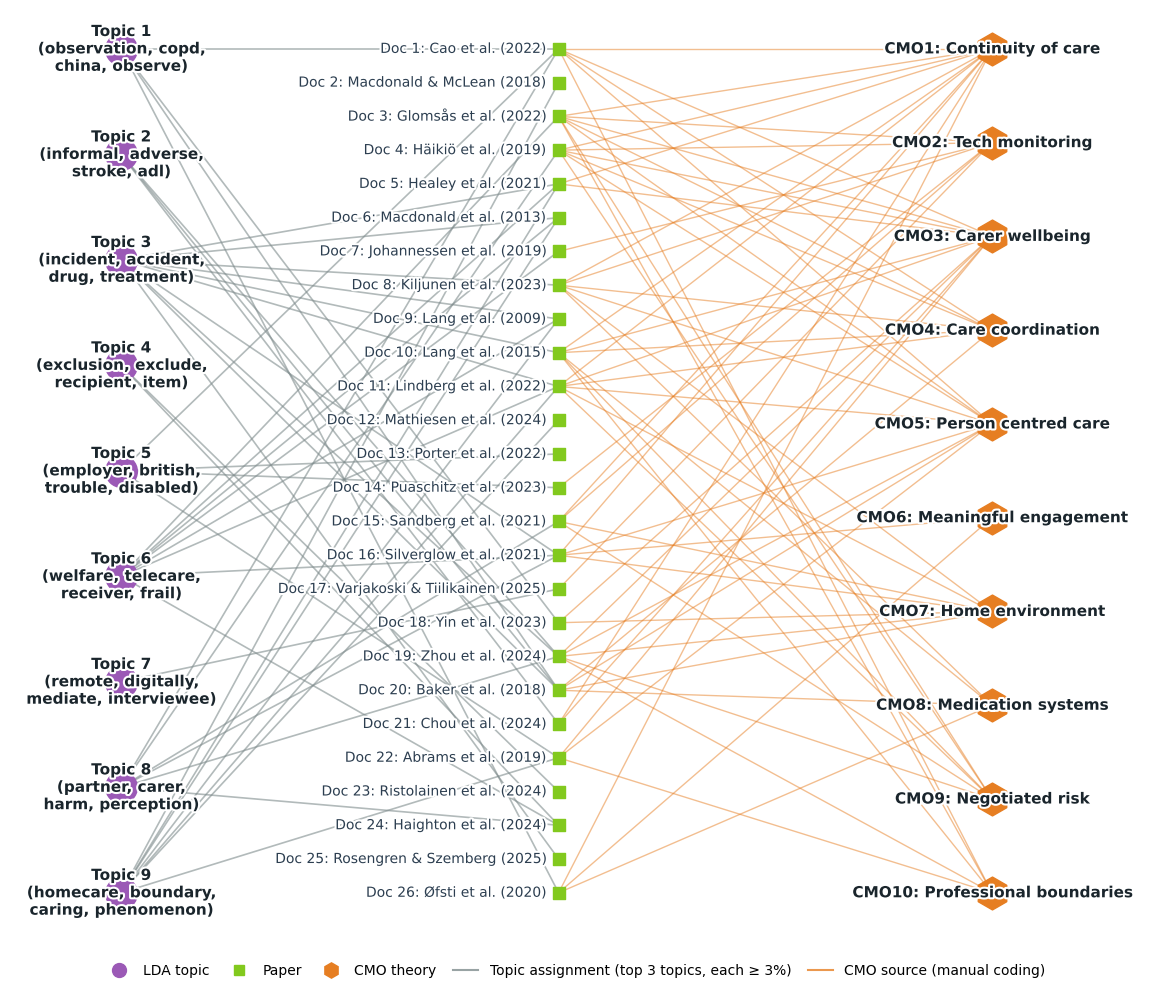

In [ ]:
# ===========================================================================
# TRIPARTITE MAP:  LDA Topics  --  Documents  --  CMO Theories
#
# Left   : the 9 LDA topics
# Middle : the 26 documents
# Right  : the 10 CMO theories, from Theories.docx
#
# The topic->document half uses EXACTLY the same edge rule as the bipartite
# map above (top 3 topics, at least 3%, uniform thickness), so the left-hand
# side of this figure matches the one you already have.
# ===========================================================================
import networkx as nx
import matplotlib.pyplot as plt
import re

try:
    show_model_stamp()
except NameError:
    print("[model stamp unavailable - run the training cell above]")

# --- Edge style for the topic side -----------------------------------------
# False = match the bipartite map above: top 3 topics >= 3%, uniform lines.
# True  = draw every topic with width proportional to probability, so each
#         document's topic edges sum to 1.0. Use this if you need the figure
#         to show that the distribution totals 1.0 per document.
WEIGHT_BY_PROBABILITY = False

TOP_N_TOPICS = 3        # used when WEIGHT_BY_PROBABILITY is False
MIN_TOPIC_PROB = 0.03

# --- CMO theory -> document mapping, transcribed from Theories.docx ---------
# Linked by citation. Note this is deliberately NOT done by searching the
# paper text for author surnames: that approach wires a paper to a theory via
# its CO-authors (it previously gave Mathiesen edges to 8 of the 10 CMOs,
# because its first author is Karoline *Lang* Mathiesen).
# Theories.docx cites "Lang" without a year. It is taken to be Lang et al. (2015):
# every theory source came from the further literature searches (Papers.docx),
# as did Lang et al. (2015), whereas Lang et al. (2009) came from the scoping searches.
LANG_AMBIGUOUS = ["Lang et al. (2015)"]

cmo_mapping = {
    "CMO1: Continuity of care": [
        "Cao et al. (2022)", "Øfsti et al. (2020)", "Silverglow et al. (2021)",
        "Chou et al. (2024)", "Häikiö et al. (2019)", "Glomsås et al. (2022)",
        "Healey et al. (2021)", "Kiljunen et al. (2023)",
        "Lindberg et al. (2022)", "Sandberg et al. (2021)"] + LANG_AMBIGUOUS,
    "CMO2: Tech monitoring": [
        "Glomsås et al. (2022)", "Häikiö et al. (2019)",
        "Johannessen et al. (2019)", "Kiljunen et al. (2023)",
        "Varjakoski & Tiilikainen (2025)", "Puaschitz et al. (2023)",
        "Sandberg et al. (2021)"],
    "CMO3: Carer wellbeing": [
        "Abrams et al. (2019)", "Cao et al. (2022)", "Chou et al. (2024)",
        "Glomsås et al. (2022)", "Yin et al. (2023)", "Zhou et al. (2024)",
        "Healey et al. (2021)", "Häikiö et al. (2019)",
        "Lindberg et al. (2022)"] + LANG_AMBIGUOUS,
    "CMO4: Care coordination": [
        "Baker et al. (2018)", "Glomsås et al. (2022)", "Cao et al. (2022)",
        "Häikiö et al. (2019)", "Lindberg et al. (2022)",
        "Kiljunen et al. (2023)"] + LANG_AMBIGUOUS,
    "CMO5: Person centred care": [
        "Abrams et al. (2019)", "Baker et al. (2018)", "Cao et al. (2022)",
        "Glomsås et al. (2022)", "Häikiö et al. (2019)", "Zhou et al. (2024)",
        "Kiljunen et al. (2023)", "Lindberg et al. (2022)",
        "Silverglow et al. (2021)"],
    "CMO6: Meaningful engagement": [
        "Øfsti et al. (2020)", "Silverglow et al. (2021)"],
    "CMO7: Home environment": [
        "Baker et al. (2018)", "Sandberg et al. (2021)",
        "Kiljunen et al. (2023)", "Yin et al. (2023)",
        "Lindberg et al. (2022)", "Silverglow et al. (2021)",
        "Zhou et al. (2024)"],
    "CMO8: Medication systems": [
        "Baker et al. (2018)", "Lang et al. (2015)",
        "Kiljunen et al. (2023)", "Øfsti et al. (2020)"],
    "CMO9: Negotiated risk": [
        "Glomsås et al. (2022)", "Lindberg et al. (2022)",
        "Sandberg et al. (2021)", "Zhou et al. (2024)",
        "Häikiö et al. (2019)"] + LANG_AMBIGUOUS,
    "CMO10: Professional boundaries": [
        "Abrams et al. (2019)", "Cao et al. (2022)", "Glomsås et al. (2022)",
        "Zhou et al. (2024)"] + LANG_AMBIGUOUS,
}

# --- Resolve documents to citations ----------------------------------------
doc_labels, doc_citations = [], []
for i_doc, raw_title in enumerate(df_papers['Title']):
    folded = fold_title(raw_title)
    citation = "Unknown Author"
    for key, val in author_map.items():
        if key in folded:
            citation = val
            break
    doc_citations.append(citation)
    doc_labels.append(f"Doc {i_doc + 1}: {citation}")

unknown = [i + 1 for i, c in enumerate(doc_citations) if c == "Unknown Author"]
if unknown:
    print(f"WARNING: unresolved citation for document(s) {unknown}")

cited = {c for v in cmo_mapping.values() for c in v}
missing = sorted(cited - set(doc_citations))
if missing:
    print("WARNING: named in cmo_mapping but absent from the corpus:")
    for m in missing:
        print(f"   - {m}")

# --- Build the graph --------------------------------------------------------
T = nx.Graph()
topic_nodes = [topic_labels_dict[t] for t in range(NUM_TOPICS)]
cmo_nodes = list(cmo_mapping.keys())

for n in topic_nodes:
    T.add_node(n, node_type='topic')
for n in doc_labels:
    T.add_node(n, node_type='document')
for n in cmo_nodes:
    T.add_node(n, node_type='cmo')

topic_edges, cmo_edges, doc_prob_sum = [], [], []

for i_doc, bow in enumerate(corpus):
    dist = sorted(lda_model.get_document_topics(bow, minimum_probability=0.0),
                  key=lambda x: x[1], reverse=True)
    shown = dist if WEIGHT_BY_PROBABILITY else [
        (t, p) for t, p in dist[:TOP_N_TOPICS] if p >= MIN_TOPIC_PROB]

    drawn = 0.0
    for tid, prob in shown:
        T.add_edge(topic_labels_dict[tid], doc_labels[i_doc], weight=float(prob))
        topic_edges.append((topic_labels_dict[tid], doc_labels[i_doc], float(prob)))
        drawn += prob
    doc_prob_sum.append((doc_labels[i_doc], drawn, len(shown)))

for cmo, papers in cmo_mapping.items():
    for i_doc, cit in enumerate(doc_citations):
        if cit in papers:
            T.add_edge(cmo, doc_labels[i_doc], weight=1.0)
            cmo_edges.append((cmo, doc_labels[i_doc]))

# --- Report -----------------------------------------------------------------
grand = sum(p for _, p, _ in doc_prob_sum)
n_docs = len(doc_prob_sum)
print(f"\nTopic -> document edges : {len(topic_edges)}")
print(f"Document -> CMO edges   : {len(cmo_edges)} (from Theories.docx)")
print(f"Topic probability drawn : {grand:.3f} of {n_docs}.000 "
      f"({grand / n_docs:.1%} per document)")
if not WEIGHT_BY_PROBABILITY and abs(grand - n_docs) > 0.01:
    print(f"   The top-{TOP_N_TOPICS}/{MIN_TOPIC_PROB:.0%} rule leaves "
          f"{n_docs - grand:.3f} undrawn, so these edges do not sum to 1.0")
    print("   per document. Quote the coverage above in the caption, or set")
    print("   WEIGHT_BY_PROBABILITY = True to draw the full distribution.")

unlinked = [d for d in doc_labels if not any(d == e[1] for e in cmo_edges)]
if unlinked:
    print(f"\n{len(unlinked)} document(s) feed into no CMO (scoping-search papers):")
    for d in unlinked:
        print(f"   - {d}")

# --- Layout: three columns, sized for the printed page -----------------------
# Drawn at twice print size: the figure is inserted 14.4 cm wide, so the 10-11 pt
# text here prints at about 5 pt. Axis units are points, so node positions and
# label widths can be set directly.
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D

FIG_W, FIG_H = 11.32, 9.8                      # inches
W_PT, H_PT = FIG_W * 72, FIG_H * 72
X_TOPIC, X_DOC, X_CMO = 80, 395, 707           # column positions (points)
Y_TOP, Y_BOT = H_PT - 28, 70                   # room for the legend underneath


def column(nodes, x):
    n = len(nodes)
    return {node: (x, Y_TOP if n == 1 else Y_TOP - (Y_TOP - Y_BOT) * k / (n - 1))
            for k, node in enumerate(nodes)}


pos = {}
pos.update(column(topic_nodes, X_TOPIC))
pos.update(column(doc_labels, X_DOC))
pos.update(column(cmo_nodes, X_CMO))

fig = plt.figure(figsize=(FIG_W, FIG_H))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, W_PT)
ax.set_ylim(0, H_PT)
ax.axis('off')
halo = [pe.withStroke(linewidth=3, foreground='white')]   # keeps text legible over lines
FONT = 'DejaVu Sans'   # bundled with matplotlib, so the figure is the same everywhere

# Edges first so that nodes and labels sit on top. Topic edges: same grey as the
# bipartite map; CMO edges: manual coding, no probability, uniform and orange.
if WEIGHT_BY_PROBABILITY:
    tw = [w for _, _, w in topic_edges]
    nx.draw_networkx_edges(
        T, pos, edgelist=[(a, b) for a, b, _ in topic_edges],
        width=[0.2 + 3.0 * w for w in tw],
        edge_color=[(0.50, 0.55, 0.55, 0.15 + 0.65 * w) for w in tw], ax=ax)
else:
    nx.draw_networkx_edges(T, pos, edgelist=[(a, b) for a, b, _ in topic_edges],
                           width=1.2, alpha=0.6, edge_color='#7F8C8D', ax=ax)
nx.draw_networkx_edges(T, pos, edgelist=cmo_edges, width=1.0,
                       alpha=0.5, edge_color='#E67E22', ax=ax)

nx.draw_networkx_nodes(T, pos, nodelist=topic_nodes, node_color='#9B59B6',
                       node_size=520, node_shape='o', ax=ax)
nx.draw_networkx_nodes(T, pos, nodelist=doc_labels, node_color='#82C91E',
                       node_size=70, node_shape='s', ax=ax)
nx.draw_networkx_nodes(T, pos, nodelist=cmo_nodes, node_color='#E67E22',
                       node_size=560, node_shape='h', ax=ax)

for n in topic_nodes + cmo_nodes:
    ax.text(*pos[n], n, ha='center', va='center', fontsize=11, fontweight='bold',
            fontfamily=FONT, color='#1A252C', path_effects=halo)
for n in doc_labels:
    x, y = pos[n]
    ax.text(x - 9, y, n, ha='right', va='center', fontsize=10,
            fontfamily=FONT, color='#2C3E50', path_effects=halo)

legend_items = [
    Line2D([], [], marker='o', ls='', color='#9B59B6', markersize=10, label='LDA topic'),
    Line2D([], [], marker='s', ls='', color='#82C91E', markersize=7, label='Paper'),
    Line2D([], [], marker='h', ls='', color='#E67E22', markersize=11, label='CMO theory'),
    Line2D([], [], color='#7F8C8D', lw=1.5, alpha=0.8,
           label=f'Topic assignment (top {TOP_N_TOPICS} topics, each ≥ {MIN_TOPIC_PROB:.0%})'),
    Line2D([], [], color='#E67E22', lw=1.5, alpha=0.8, label='CMO source (manual coding)'),
]
ax.legend(handles=legend_items, loc='lower center', bbox_to_anchor=(0.5, 0.0), ncol=5,
          prop={'family': FONT, 'size': 10}, frameon=False, handlelength=1.8, columnspacing=1.2)

plt.savefig("tripartite_topic_document_cmo_map.png", dpi=300, bbox_inches='tight',
            pad_inches=0.05)
plt.show()

In [ ]:
# Per-document topic diagnostic.
#
# Reports each document's dominant topic and how concentrated it is. A corpus
# where nearly every document sits on one topic means the model is separating
# documents rather than finding shared themes -- see the coherence table above.

# --- Guard against stale state ---------------------------------------------
# If the JSON was reloaded without re-running preprocessing, `corpus` and
# `df_papers` fall out of step and every label silently attaches to the wrong
# paper. Fail loudly instead.
try:
    show_model_stamp()
except NameError:
    print("[model stamp unavailable - run the training cell above]")


if len(corpus) != len(df_papers):
    raise RuntimeError(
        f"corpus has {len(corpus)} documents but df_papers has {len(df_papers)}. "
        "The notebook has been run out of order -- use Runtime > Restart session "
        "and run all so every cell sees the same data.")

# Occurrences per 1,000 tokens of the assigned topic's top-10 keywords,
# below which the assignment is not really grounded in that topic's words.
LOW_SUPPORT_PER_1K = 10.0

single_topic, topic_mass = 0, [0.0] * NUM_TOPICS
weak_support = []

print(f"{'document':40s} {'top':>4} {'share':>7} {'>10%':>5} {'kw/1k':>7} {'len':>6}")
print("-" * 74)

for i_doc, bow in enumerate(corpus):
    citation = "Unknown Author"
    folded = fold_title(df_papers['Title'].iloc[i_doc])
    for key, val in author_map.items():
        if key in folded:
            citation = val
            break

    dist = lda_model.get_document_topics(bow, minimum_probability=0.0)
    for t, p in dist:
        topic_mass[t] += p

    top_topic, top_prob = max(dist, key=lambda x: x[1])
    n_above10 = sum(1 for _, p in dist if p >= 0.10)
    if n_above10 <= 1:
        single_topic += 1

    # Keyword support: how often does the assigned topic's OWN vocabulary
    # actually occur in this paper? A high share with little keyword support
    # means the document was placed there by elimination rather than by
    # content -- which happens easily to short papers.
    tokens = processed_docs[i_doc]
    kw = {w for w, _ in lda_model.show_topic(top_topic, topn=10)}
    hits = sum(1 for t in tokens if t in kw)
    per1k = hits / max(len(tokens), 1) * 1000
    if per1k < LOW_SUPPORT_PER_1K:
        weak_support.append((i_doc + 1, citation, top_topic + 1, per1k, len(tokens)))

    flag = " <-- weak" if per1k < LOW_SUPPORT_PER_1K else ""
    label = f"Doc {i_doc + 1}: {citation}"
    print(f"{label:40s} {top_topic + 1:4d} {top_prob:7.1%} {n_above10:5d} "
          f"{per1k:7.1f} {len(tokens):6d}{flag}")

dead_topics = [t + 1 for t, m in enumerate(topic_mass) if m < 0.5]

if weak_support:
    print("\n" + "-" * 74)
    print("WEAKLY SUPPORTED ASSIGNMENTS -- high confidence, little matching vocabulary:")
    for n, cit, t, rate, ln in sorted(weak_support, key=lambda z: z[3]):
        print(f"   Doc {n} {cit}: Topic {t}, only {rate:.1f} keyword "
              f"hits per 1k tokens ({ln} tokens)")
    print("   LDA always returns a distribution, so a paper with little")
    print("   distinctive vocabulary still gets a confident-looking share.")
    print("   Short papers are especially prone to this. Treat these dominant")
    print("   topics as provisional and check the paper before citing it as")
    print("   evidence for that theme.")

print("\n" + "=" * 62)
print(f"{single_topic} of {len(corpus)} documents have only one topic above 10%.")
if dead_topics:
    print(f"Unused topics (almost no document mass): {dead_topics}")

if single_topic > 0.6 * len(corpus):
    print("\nMost documents sit on a single topic. Before reacting to that, check")
    print("the keyword overlap printed by the topic-keywords cell:")
    print()
    print("  - Topics OVERLAP heavily (worst pair above ~0.4)?")
    print("      The model is undertrained. Raise `passes` in the diagnostic cell.")
    print("      Do NOT lower NUM_TOPICS -- an undertrained model spreads every")
    print("      document thinly and only LOOKS mixed.")
    print()
    print("  - Topics well SEPARATED (low overlap, healthy word weights)?")
    print("      Then this is most likely a real property of a small corpus of")
    print("      focused papers, not a defect. Report each paper's dominant topic,")
    print("      describe the model as identifying primary thematic focus, and note")
    print("      the corpus size as a limitation. Do not tune it away.")

[model: K=9, passes=15, alpha='50/K', run #1]
document                                  top   share  >10%   kw/1k    len
--------------------------------------------------------------------------
Doc 1: Cao et al. (2022)                    8   73.7%     1    41.1   1970
Doc 2: Macdonald & McLean (2018)            9   91.5%     1    29.6   2703
Doc 3: Glomsås et al. (2022)                6   93.4%     1    51.2   4353
Doc 4: Häikiö et al. (2019)                 8   89.7%     1    35.3   3453
Doc 5: Healey et al. (2021)                 9   59.7%     2     4.4    909 <-- weak
Doc 6: Macdonald et al. (2013)              6   70.5%     1     1.4   2935 <-- weak
Doc 7: Johannessen et al. (2019)            6   90.5%     1    56.6   2652
Doc 8: Kiljunen et al. (2023)               3   88.9%     1    71.9   2559
Doc 9: Lang et al. (2009)                   3   38.7%     3     1.8   1693 <-- weak
Doc 10: Lang et al. (2015)                  3   92.0%     1     6.0   4195 <-- weak
Doc 11: Lindberg e